In [ ]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jaxopt import AndersonAcceleration
import pickle


In [ ]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

In [ ]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    y_max_g = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g, y_max_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g) * y_max_g

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass y_max_g as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_y_max(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, y_max_g):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g, y_max_g)

    aa = AndersonAcceleration(fixed_point_with_y_max, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, y_max_g)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

In [ ]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562


## 4. Load params, test stability 



In [ ]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_xx_zz.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

In [ ]:
theta_opt.shape
PARAM_NAMES = [
    r"$w_{\mathrm{OSN},r}$",
    r"$w_{\mathrm{OSN},b}$",
    r"$w_{\mathrm{OSN},g}$",
    r"$w_{\mathrm{OSN},y}$",
    r"$w_{b,r}$",
    r"$w_{b,g}$",
    r"$w_{b,y}$",
    r"$w_{r,y}$",
    r"$w_{r,g}$",
    r"$\alpha$",
    r"$W_{g, r}$",
    r"$W_{g, y}$",
    r"$y_{\max,g}$",
]

param_idx = np.arange(theta_opt.shape[1])
fig, ax = plt.subplots(figsize=(8, 6))
for i in range(theta_opt.shape[0]):
    ax.plot(param_idx, theta_opt[i, :], 'o', label=f'Sample {i+1}')
ax.set_xticks(param_idx)
ax.set_xticklabels(PARAM_NAMES, rotation=40, ha='right', fontsize=20)
ax.tick_params(axis='y', labelsize=20)
ax.tick_params(axis='x', labelsize=20)
ax.set_xlabel('Parameter', fontsize=22)
ax.set_ylabel('Parameter Value', fontsize=22)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig('Figures_final/theta_opt_raw.eps')
plt.show()


In [ ]:
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

In [ ]:
# Define the dynamics function F(s, theta, x, m) 
# State vector s = [r, g, y]
def F(s, theta, x, m, n_r=1.850, n_b=0.642, n_g=1.868, n_y=1.562):
    """
    Dynamics function that computes the next state from current state s.
    """
    # Unpack state vector
    r = s[:m]
    g = s[m:2*m]
    y = s[2*m:3*m]

    # Unpack parameters
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)

    # Compute b (doesn't depend on state, only on input)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r_new = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    g_new = nr(w_osn_g * alpha * x - w_b_g * b + w_r_g * r, n=n_g) * y_max_g
    y_new = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g_new + w_r_y * r_new, n=n_y)

    # Return concatenated state vector
    s_prime = jnp.concatenate([r_new, g_new, y_new])
    return s_prime

# Compute Jacobian matrix J = dF/ds at the fixed point s_star
def compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y):
    # Create a function that only depends on s (for JAX differentiation)
    def F_s(s):
        return F(s, theta, x, m, n_r, n_b, n_g, n_y)

    # jax.jacobian computes the Jacobian matrix: J[i,j] = dF_i/ds_j
    J = jax.jacobian(F_s)(s_star)
    return J

# Compute matrix A and check stability
def compute_stability(F, s_star, theta, x, m, tau=1.0, n_r=1.850, n_b=0.642, n_g=1.868, n_y=1.562):
    n = s_star.shape[0]
    I = jnp.eye(n)
    J = compute_jacobian(F, s_star, theta, x, m, n_r, n_b, n_g, n_y)
    A = (1 / tau) * (J - I)

    eigenvalues = jnp.linalg.eigvals(A)
    eigenvalues_np = np.array(eigenvalues)

    # Check stability - all eigenvalues must have negative real parts
    real_parts = np.real(eigenvalues_np)
    is_stable = np.all(real_parts < 0.0)

    return {
        'J': J,
        'A': A,
        'eigenvalues': eigenvalues_np,
        'is_stable': is_stable,
        'real_parts': real_parts,
        'imag_parts': np.imag(eigenvalues_np)
    }


In [ ]:
# Analyse all converged samples
n_samples_to_analyze = theta_opt.shape[0]

theta_subset = theta_opt[:n_samples_to_analyze]
print(f"Using {n_samples_to_analyze} samples for stability")


In [ ]:
stability_results_all = {}
stability_results = []
max_real_parts = []
min_real_parts = []
all_eigenvalues = []

for i in range(n_samples_to_analyze):
    theta_star = theta_subset[i, :]

    # Get fixed point outputs with new n values
    try:
        r_star, g_star, b_star, y_star = mitral_output(theta_star, x, m, n_r, n_b, n_g, n_y)

        # Construct state vector s* = [r, g, y]
        s_star = jnp.concatenate([r_star, g_star, y_star])

        # Verify it's a fixed point
        s_prime = F(s_star, theta_star, x, m, n_r, n_b, n_g, n_y)
        s_error = jnp.linalg.norm(s_prime - s_star)

        # Compute stability
        result = compute_stability(F, s_star, theta_star, x, m, tau=1.0, n_r=n_r, n_b=n_b, n_g=n_g, n_y=n_y)
        stability_results.append(result)

        max_real_parts.append(np.max(result['real_parts']))
        min_real_parts.append(np.min(result['real_parts']))
        all_eigenvalues.append(result['eigenvalues'])

    except Exception as e:
        print(f"  Sample {i+1}: Error - {e}")
        continue


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


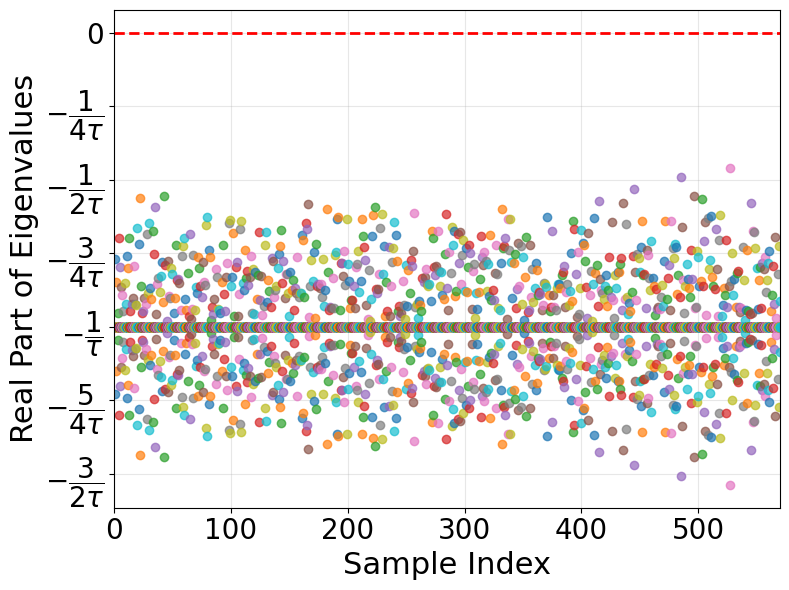


STABILITY SUMMARY

Stable samples: 570/570 (100.0%)


In [ ]:
# visualise stability results
from fractions import Fraction
from matplotlib.ticker import FixedLocator

def y_tick_frac_label(k_quarters):
    """Label for tick at -k_quarters/(4*tau): minus sign outside stacked fraction."""
    if k_quarters == 0:
        return '0'
    f = Fraction(k_quarters, 4)
    num, den = f.numerator, f.denominator
    if den == 1:
        return rf'$-\dfrac{{{num}}}{{\tau}}$'
    return rf'$-\dfrac{{{num}}}{{{den}\tau}}$'

tau = 1.0  
fig, ax1 = plt.subplots(1, 1, figsize=(8, 6))

# use actual number of samples
actual_no_samples = len(stability_results)
all_real_parts = np.concatenate([r['real_parts'] for r in stability_results])
y_min_data = np.min(all_real_parts)

for i in range(actual_no_samples):
    real_parts = stability_results[i]['real_parts']
    ax1.plot([i+1] * len(real_parts), real_parts, 'o', alpha=0.7, label=f'Sample {i+1}' if i < 5 else '')
ax1.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Stability threshold')
ax1.set_xlabel('Sample Index', fontsize=22)
ax1.set_ylabel('Real Part of Eigenvalues', fontsize=22)
actual_no_samples = len(stability_results)
ax1.set_xlim(0, actual_no_samples)

# y limits: just above stability line (y=0) and just past most negative eigenvalue
y_pad = max(0.02, 0.05 * abs(y_min_data))
y_top = y_pad
y_bottom = y_min_data - y_pad

# quarter-tau ticks
k_max = int(np.ceil(-y_bottom * 4 * tau))
y_tick_positions = [-k / (4 * tau) for k in range(0, k_max + 1)]
y_tick_labels = [y_tick_frac_label(k) for k in range(0, k_max + 1)]
ax1.set_ylim(y_bottom, y_top)
ax1.yaxis.set_major_locator(FixedLocator(y_tick_positions))
ax1.set_yticklabels(y_tick_labels)
ax1.grid(True, alpha=0.3)

stable_count = sum(1 for r in stability_results if r['is_stable'])
unstable_count = actual_no_samples - stable_count

plt.tight_layout()
plt.tick_params(axis='both', direction='out')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)

plt.tight_layout()
plt.savefig('Figures_final/stability.eps')
plt.show()

# print summary
print("\n" + "=" * 70)
print("STABILITY SUMMARY")
print("=" * 70)
print(f"\nStable samples: {stable_count}/{actual_no_samples} ({100*stable_count/actual_no_samples:.1f}%)")


In [ ]:
# remove unstable theta
theta_opt = np.array(theta_opt)
remove_row = [i for i, r in enumerate(stability_results) if not r['is_stable']]
max_index = theta_opt.shape[0] - 1
valid_remove_row = [i for i in remove_row if 0 <= i <= max_index]

for i in sorted(valid_remove_row, reverse=True):
    theta_opt = np.delete(theta_opt, i, axis=0)